In [220]:
import pandas as pd
df=pd.read_csv('/content/ml_order_dataset.csv')
df.head()

,order_id,customer_id,customer_state,order_purchase_timestamp,item_count,total_price,total_freight,seller_count,product_count,total_payment_value,max_installments,payment_type_count,payment_types,category_count,product_categories,avg_product_weight_g,late_delivery
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,RJ,2017-09-13 08:59:02,1,58.90,13.29,1,1,72.19,2.0,1.0,credit_card,1,cool_stuff,650.0,0
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,SP,2017-04-26 10:53:06,1,239.90,19.93,1,1,259.83,3.0,1.0,credit_card,1,pet_shop,30000.0,0
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,MG,2018-01-14 14:33:31,1,199.00,17.87,1,1,216.87,5.0,1.0,credit_card,1,furniture_decor,3050.0,0
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,SP,2018-08-08 10:00:35,1,12.99,12.79,1,1,25.78,2.0,1.0,credit_card,1,perfumery,200.0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,SP,2017-02-04 13:57:51,1,199.90,18.14,1,1,218.04,3.0,1.0,credit_card,1,garden_tools,3750.0,0


In [221]:
df.shape

(95089, 17)

In [222]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95089 entries, 0 to 95088
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  95089 non-null  object 
 1   customer_id               95089 non-null  object 
 2   customer_state            95089 non-null  object 
 3   order_purchase_timestamp  95089 non-null  object 
 4   item_count                95089 non-null  int64  
 5   total_price               95089 non-null  float64
 6   total_freight             95089 non-null  float64
 7   seller_count              95089 non-null  int64  
 8   product_count             95089 non-null  int64  
 9   total_payment_value       95088 non-null  float64
 10  max_installments          95088 non-null  float64
 11  payment_type_count        95088 non-null  float64
 12  payment_types             95088 non-null  object 
 13  category_count            95089 non-null  int64  
 14  produc

In [223]:
df.describe()

,item_count,total_price,total_freight,seller_count,product_count,total_payment_value,max_installments,payment_type_count,category_count,avg_product_weight_g,late_delivery
count,95089.000000,95089.000000,95089.000000,95089.000000,95089.000000,95088.000000,95088.000000,95088.000000,95089.000000,95073.000000,95089.000000
mean,1.141972,137.177040,22.772617,1.013493,1.038185,159.979955,2.929823,1.022621,0.993343,2104.105628,0.081965
std,0.538613,209.501699,21.584901,0.121152,0.226967,219.268468,2.715068,0.148693,0.147786,3756.121449,0.274313
min,1.000000,0.850000,0.000000,1.000000,1.000000,9.590000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,1.000000,45.900000,13.840000,1.000000,1.000000,61.850000,1.000000,1.000000,1.000000,300.000000,0.000000
50%,1.000000,86.600000,17.160000,1.000000,1.000000,105.280000,2.000000,1.000000,1.000000,700.000000,0.000000
75%,1.000000,149.900000,24.000000,1.000000,1.000000,176.352500,4.000000,1.000000,1.000000,1813.000000,0.000000
max,21.000000,13440.000000,1794.960000,5.000000,8.000000,13664.080000,24.000000,2.000000,3.000000,40425.000000,1.000000


In [224]:
df['order_purchase_timestamp']=pd.to_datetime(df['order_purchase_timestamp'])

In [225]:
df.dtypes

,0
order_id,object
customer_id,object
customer_state,object
order_purchase_timestamp,datetime64[ns]
item_count,int64
total_price,float64
total_freight,float64
seller_count,int64
product_count,int64
total_payment_value,float64


In [226]:
df['late_delivery'].value_counts()

,count
late_delivery,
0,87295
1,7794


In [227]:
df.isnull().sum()

,0
order_id,0
customer_id,0
customer_state,0
order_purchase_timestamp,0
item_count,0
total_price,0
total_freight,0
seller_count,0
product_count,0
total_payment_value,1


In [228]:
df.duplicated().sum()

np.int64(0)

In [229]:
df['order_id'].duplicated().sum()

np.int64(0)

In [230]:
df['purchase_year'] = df['order_purchase_timestamp'].dt.year
df['purchase_month'] = df['order_purchase_timestamp'].dt.month
df['purchase_day'] = df['order_purchase_timestamp'].dt.day
df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.dayofweek
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour

In [231]:
df[['order_purchase_timestamp',
    'purchase_year',
    'purchase_month',
    'purchase_dayofweek',
    'purchase_hour']].head()

,order_purchase_timestamp,purchase_year,purchase_month,purchase_dayofweek,purchase_hour
0,2017-09-13 08:59:02,2017,9,2,8
1,2017-04-26 10:53:06,2017,4,2,10
2,2018-01-14 14:33:31,2018,1,6,14
3,2018-08-08 10:00:35,2018,8,2,10
4,2017-02-04 13:57:51,2017,2,5,13


New x and y

In [232]:
df_distance = df.merge(
    order_avg_distance,
    on='order_id',
    how='left'
)

In [233]:
df_distance[['order_id', 'seller_customer_distance_km']].head()

,order_id,seller_customer_distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,NaN
1,00018f77f2f0320c557190d7a144bdd3,585.068784
2,000229ec398224ef6ca0657da4fc703e,NaN
3,00024acbcdf0a6daa1e931b038114c75,295.481182
4,00042b26cf59d7ce69dfabb4e55b4fd9,NaN


In [234]:
df_distance['seller_customer_distance_km'].isna().value_counts()

,count
seller_customer_distance_km,
True,63107
False,31982


In [235]:
df_distance.groupby(
    df_distance['seller_customer_distance_km'].isna()
)['late_delivery'].mean()

,late_delivery
seller_customer_distance_km,
False,0.065662
True,0.090228


In [236]:
df_distance.groupby(
    pd.qcut(
        df_distance['seller_customer_distance_km'],
        5,
        duplicates='drop'
    )
)['late_delivery'].mean()

/tmp/ipykernel_4488/3127693787.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_distance.groupby(


,late_delivery
seller_customer_distance_km,
"(-0.001, 24.222]",0.062217
"(24.222, 74.806]",0.066125
"(74.806, 151.344]",0.069742
"(151.344, 309.192]",0.058474
"(309.192, 874.334]",0.071752


In [237]:
df_distance['seller_customer_distance_km'].describe()

,seller_customer_distance_km
count,31982.000000
mean,163.640811
std,152.918534
min,0.000000
25%,31.828608
50%,102.912011
75%,292.511574
max,874.334420


In [238]:
df_distance['distance_missing'] = (
    df_distance['seller_customer_distance_km'].isna().astype(int)
)

In [239]:
df_distance[['seller_customer_distance_km', 'distance_missing']].head()

,seller_customer_distance_km,distance_missing
0,NaN,1
1,585.068784,0
2,NaN,1
3,295.481182,0
4,NaN,1


In [240]:
median_distance = df_distance['seller_customer_distance_km'].median()

df_distance['seller_customer_distance_km'] = (
    df_distance['seller_customer_distance_km'].fillna(median_distance)
)

In [241]:
df_distance[['seller_customer_distance_km', 'distance_missing']].isna().sum()

,0
seller_customer_distance_km,0
distance_missing,0


In [242]:
x_new = df_distance.drop(columns='late_delivery')

y_new = df_distance['late_delivery']

In [243]:
x_new = x_new.drop(
    columns=[
        'order_id',
        'customer_id',
        'order_purchase_timestamp',
        'purchase_day'
    ]
)

In [245]:
x_new.shape,y_new.shape

((95089, 19), (95089,))

In [246]:
x_train_new, x_test_new, y_train_new, y_test_new = train_test_split(
    x_new,
    y_new,
    test_size=0.2,
    stratify=y_new,
    random_state=42
)

In [247]:
x_train_new.shape, x_test_new.shape

((76071, 19), (19018, 19))

In [248]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_cols_new = x_train_new.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols_new = x_train_new.select_dtypes(
    include=['object']
).columns

In [249]:
numerical_cols_new.tolist(), categorical_cols_new.tolist()

(['item_count',
  'total_price',
  'total_freight',
  'seller_count',
  'product_count',
  'total_payment_value',
  'max_installments',
  'payment_type_count',
  'category_count',
  'avg_product_weight_g',
  'seller_customer_distance_km',
  'distance_missing'],
 ['customer_state', 'payment_types', 'product_categories'])

In [250]:
df_distance.columns.tolist()

['order_id',
 'customer_id',
 'customer_state',
 'order_purchase_timestamp',
 'item_count',
 'total_price',
 'total_freight',
 'seller_count',
 'product_count',
 'total_payment_value',
 'max_installments',
 'payment_type_count',
 'payment_types',
 'category_count',
 'product_categories',
 'avg_product_weight_g',
 'late_delivery',
 'purchase_year',
 'purchase_month',
 'purchase_day',
 'purchase_dayofweek',
 'purchase_hour',
 'seller_customer_distance_km',
 'distance_missing']

In [251]:
x_new = df_distance.drop(
    columns=[
        'late_delivery',
        'order_id',
        'customer_id',
        'order_purchase_timestamp',
        'purchase_day'
    ]
)

y_new = df_distance['late_delivery']

In [252]:
x_new.shape

(95089, 19)

In [253]:
x_new.columns.tolist()

['customer_state',
 'item_count',
 'total_price',
 'total_freight',
 'seller_count',
 'product_count',
 'total_payment_value',
 'max_installments',
 'payment_type_count',
 'payment_types',
 'category_count',
 'product_categories',
 'avg_product_weight_g',
 'purchase_year',
 'purchase_month',
 'purchase_dayofweek',
 'purchase_hour',
 'seller_customer_distance_km',
 'distance_missing']

In [254]:
numerical_cols_new = x_new.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols_new = x_new.select_dtypes(
    include=['object']
).columns

print("Numerical columns:")
print(numerical_cols_new.tolist())

print("\nCategorical columns:")
print(categorical_cols_new.tolist())

Numerical columns:
['item_count', 'total_price', 'total_freight', 'seller_count', 'product_count', 'total_payment_value', 'max_installments', 'payment_type_count', 'category_count', 'avg_product_weight_g', 'seller_customer_distance_km', 'distance_missing']

Categorical columns:
['customer_state', 'payment_types', 'product_categories']


In [255]:
x_new[
    ['purchase_year',
     'purchase_month',
     'purchase_dayofweek',
     'purchase_hour']
].dtypes

,0
purchase_year,int32
purchase_month,int32
purchase_dayofweek,int32
purchase_hour,int32


In [256]:
numerical_cols_new = x_new.select_dtypes(
    include=['number']
).columns

categorical_cols_new = x_new.select_dtypes(
    include=['object']
).columns

print("Numerical columns:")
print(numerical_cols_new.tolist())

print("\nCategorical columns:")
print(categorical_cols_new.tolist())

Numerical columns:
['item_count', 'total_price', 'total_freight', 'seller_count', 'product_count', 'total_payment_value', 'max_installments', 'payment_type_count', 'category_count', 'avg_product_weight_g', 'purchase_year', 'purchase_month', 'purchase_dayofweek', 'purchase_hour', 'seller_customer_distance_km', 'distance_missing']

Categorical columns:
['customer_state', 'payment_types', 'product_categories']


In [257]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_new = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols_new),
    ('cat', categorical_pipeline, categorical_cols_new)
])

Training

In [258]:
x_train_new_processed = preprocessor_new.fit_transform(x_train_new)

x_test_new_processed = preprocessor_new.transform(x_test_new)

In [259]:
x_train_new_processed.shape, x_test_new_processed.shape

((76071, 320), (19018, 320))

In [260]:
x_train_new_processed = x_train_new_processed.toarray()
x_test_new_processed = x_test_new_processed.toarray()

In [261]:
x_train_new_processed.shape

(76071, 320)

In [262]:
from sklearn.ensemble import GradientBoostingClassifier

gb_distance = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

gb_distance.fit(
    x_train_new_processed,
    y_train_new
)

GradientBoostingClassifier(max_depth=4, random_state=42)

In [263]:
y_test_prob_distance = gb_distance.predict_proba(
    x_test_new_processed
)[:, 1]

In [264]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_train_prob_distance_oof = cross_val_predict(
    gb_distance,
    x_train_new_processed,
    y_train_new,
    cv=cv,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

In [265]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_train_new,
    y_train_prob_distance_oof
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_threshold_distance = thresholds[best_idx]
best_f1_distance = f1_scores[best_idx]

print("Best threshold:", best_threshold_distance)
print("OOF F1:", best_f1_distance)

Best threshold: 0.1350221668305745
OOF F1: 0.3186028673792986


In [266]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_test_pred_distance = (
    y_test_prob_distance >= best_threshold_distance
).astype(int)

print("Accuracy:", accuracy_score(y_test_new, y_test_pred_distance))
print("Precision:", precision_score(y_test_new, y_test_pred_distance))
print("Recall:", recall_score(y_test_new, y_test_pred_distance))
print("F1:", f1_score(y_test_new, y_test_pred_distance))
print("ROC-AUC:", roc_auc_score(y_test_new, y_test_prob_distance))

Accuracy: 0.8499316437059627
Precision: 0.25067385444743934
Recall: 0.41757536882617063
F1: 0.31328200192492783
ROC-AUC: 0.7415658259333946


In [270]:
feature_importance_df.head(15)

,feature,importance
11,num__purchase_month,0.402828
10,num__purchase_year,0.157059
32,cat__customer_state_RJ,0.098601
39,cat__customer_state_SP,0.066268
2,num__total_freight,0.056913
24,cat__customer_state_MG,0.022131
9,num__avg_product_weight_g,0.021942
18,cat__customer_state_BA,0.016857
31,cat__customer_state_PR,0.016034
23,cat__customer_state_MA,0.012861


In [269]:
%whos

Variable                     Type                          Data/Info
--------------------------------------------------------------------
ColumnTransformer            ABCMeta                       <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DecisionTreeClassifier       ABCMeta                       <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GradientBoostingClassifier   ABCMeta                       <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
LassoCV                      ABCMeta                       <class 'sklearn.linear_mo<...>rdinate_descent.LassoCV'>
LogisticRegression           type                          <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                type                          <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                     ABCMeta                       <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier       ABCMeta                       <class 'sklearn.en

In [271]:
print(final_tuned_gb)
print(x_train_processed.shape)
print(x_test_processed.shape)

GradientBoostingClassifier(max_depth=4, random_state=42)
(76071, 316)
(19018, 316)


In [272]:
test_probabilities = final_tuned_gb.predict_proba(x_test_processed)[:, 1]

test_probabilities[:10]

array([0.09575825, 0.15078322, 0.04041092, 0.03142624, 0.09959212,
       0.03375039, 0.07727273, 0.12854398, 0.05903219, 0.03790489])

In [273]:
test_predictions = (
    test_probabilities >= final_threshold_tuned
).astype(int)

test_predictions[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [274]:
x_test.index[:10]

Index([77639, 40814, 32124, 52218, 40406, 63730, 93857, 39304, 9427, 24039], dtype='int64')

In [275]:
test_predictions_df = df.loc[x_test.index, ['order_id']].copy()

test_predictions_df['late_risk_probability'] = test_probabilities
test_predictions_df['predicted_late_delivery'] = test_predictions

test_predictions_df.head(10)

,order_id,late_risk_probability,predicted_late_delivery
77639,d0bec96aad189992b278688279ba1511,0.095758,0
40814,6ded0b6cf54a34efba0b47373230a63b,0.150783,1
32124,566fe59dc8f089f27c0e739a3891581a,0.040411,0
52218,8d362590a388a3c9c7de2dbb72edc957,0.031426,0
40406,6cc462dbd8849dc8a1ac2f9023901fe6,0.099592,0
63730,ac0f0875604883bfc9fa15344f01a207,0.033750,0
93857,fcaa22948cf53b9b3ff7de0c67b6391c,0.077273,0
39304,69dca366b923580fca5a6c04992098c2,0.128544,0
9427,19559da3ec491caeab77c1512d28399b,0.059032,0
24039,40e370756cfe851295bf0ca9e6811f46,0.037905,0


In [276]:
all_processed = np.empty(
    (len(df), x_train_processed.shape[1])
)

all_processed[x_train.index] = x_train_processed
all_processed[x_test.index] = x_test_processed

all_processed.shape

(95089, 316)

In [277]:
all_probabilities = final_tuned_gb.predict_proba(all_processed)[:, 1]

all_probabilities[:10]

array([0.04639243, 0.06272788, 0.04300048, 0.06255256, 0.04291069,
       0.04133515, 0.03179592, 0.13716057, 0.05690286, 0.07088007])

In [278]:
all_predictions = (
    all_probabilities >= final_threshold_tuned
).astype(int)

all_predictions[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [279]:
all_predictions.sum()

np.int64(12247)

In [280]:
prediction_df = df[['order_id']].copy()

prediction_df['late_risk_probability'] = all_probabilities
prediction_df['predicted_late_delivery'] = all_predictions

prediction_df.head(10)

,order_id,late_risk_probability,predicted_late_delivery
0,00010242fe8c5a6d1ba2dd792cb16214,0.046392,0
1,00018f77f2f0320c557190d7a144bdd3,0.062728,0
2,000229ec398224ef6ca0657da4fc703e,0.043000,0
3,00024acbcdf0a6daa1e931b038114c75,0.062553,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,0.042911,0
5,00048cc3ae777c65dbb7d2a0634bc1ea,0.041335,0
6,00054e8431b9d7675808bcb819fb4a32,0.031796,0
7,0005a1a1728c9d785b8e2b08b904576c,0.137161,0
8,0005f50442cb953dcd1d21e1fb923495,0.056903,0
9,00061f2a7bc09da83e415a52dc8a4af1,0.070880,0


In [281]:
prediction_df['predicted_late_delivery'].value_counts()

,count
predicted_late_delivery,
0,82842
1,12247


## Avg product weight

In [ ]:
numeric_cols = [
    'item_count',
    'total_price',
    'total_freight',
    'seller_count',
    'product_count',
    'total_payment_value',
    'max_installments',
    'payment_type_count',
    'category_count',
    'avg_product_weight_g',
    'purchase_month',
    'purchase_dayofweek',
    'purchase_hour'
]

df.groupby('late_delivery')[numeric_cols].mean().T

late_delivery,0,1
item_count,1.144499,1.113677
total_price,136.196787,148.156159
total_freight,22.609016,24.604994
seller_count,1.014491,1.002309
product_count,1.039659,1.021683
total_payment_value,158.836393,172.789811
max_installments,2.922665,3.010009
payment_type_count,1.022876,1.019761
category_count,0.993940,0.986656
avg_product_weight_g,2077.956836,2396.925796


<Figure size 800x500 with 0 Axes>

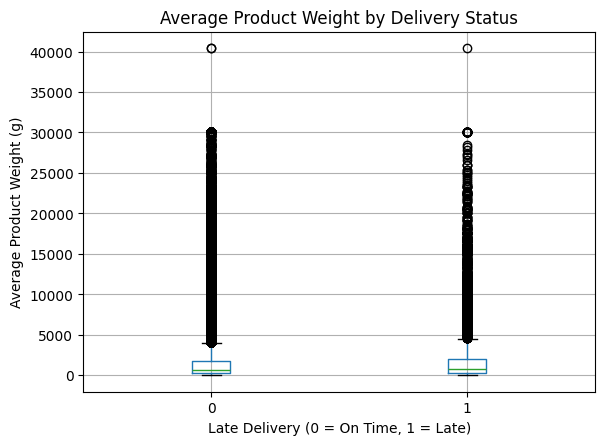

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df.boxplot(
    column='avg_product_weight_g',
    by='late_delivery'
)

plt.title('Average Product Weight by Delivery Status')
plt.suptitle('')
plt.xlabel('Late Delivery (0 = On Time, 1 = Late)')
plt.ylabel('Average Product Weight (g)')
plt.show()

/tmp/ipykernel_4488/3936054054.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


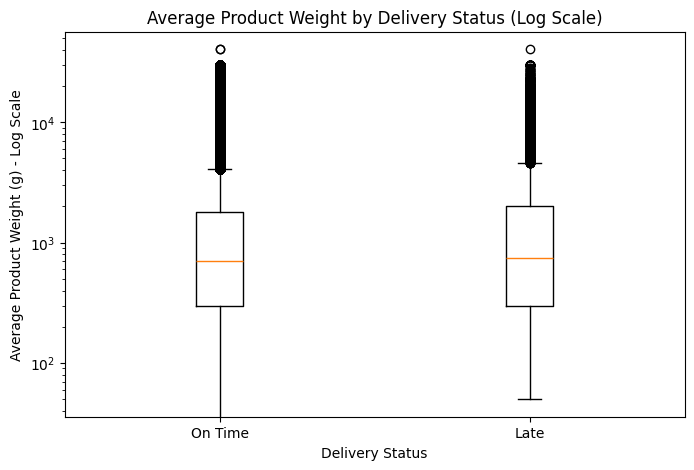

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df['late_delivery'] == 0, 'avg_product_weight_g'].dropna(),
        df.loc[df['late_delivery'] == 1, 'avg_product_weight_g'].dropna()
    ],
    labels=['On Time', 'Late']
)

plt.yscale('log')
plt.title('Average Product Weight by Delivery Status (Log Scale)')
plt.xlabel('Delivery Status')
plt.ylabel('Average Product Weight (g) - Log Scale')
plt.show()

## Total friehgt

/tmp/ipykernel_4488/2260156119.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


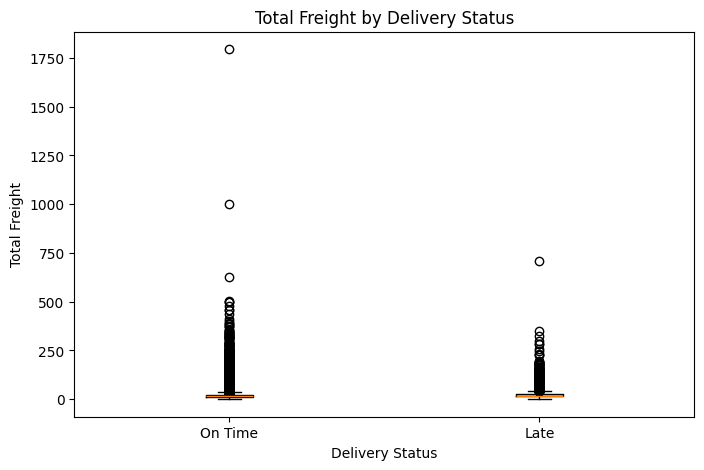

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df['late_delivery'] == 0, 'total_freight'].dropna(),
        df.loc[df['late_delivery'] == 1, 'total_freight'].dropna()
    ],
    labels=['On Time', 'Late']
)

plt.title('Total Freight by Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Total Freight')
plt.show()

/tmp/ipykernel_4488/2500365050.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


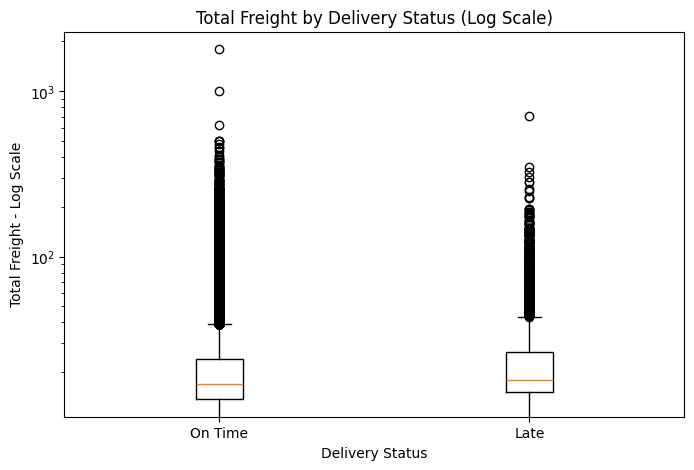

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df['late_delivery'] == 0, 'total_freight'].dropna(),
        df.loc[df['late_delivery'] == 1, 'total_freight'].dropna()
    ],
    labels=['On Time', 'Late']
)

plt.yscale('log')
plt.title('Total Freight by Delivery Status (Log Scale)')
plt.xlabel('Delivery Status')
plt.ylabel('Total Freight - Log Scale')
plt.show()

## Total price

/tmp/ipykernel_4488/2614433469.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


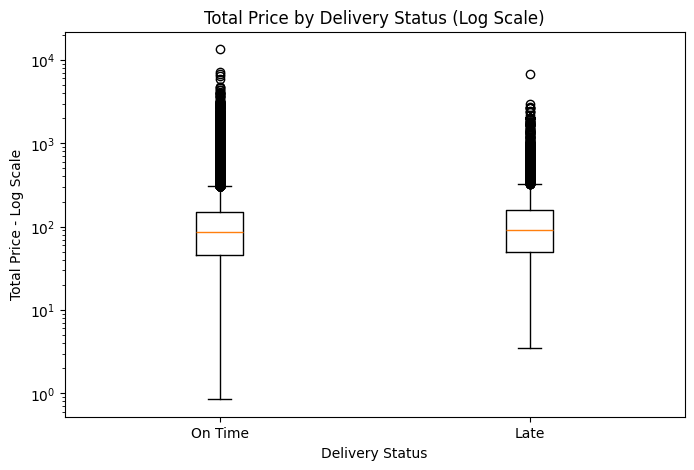

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df['late_delivery'] == 0, 'total_price'].dropna(),
        df.loc[df['late_delivery'] == 1, 'total_price'].dropna()
    ],
    labels=['On Time', 'Late']
)

plt.yscale('log')
plt.title('Total Price by Delivery Status (Log Scale)')
plt.xlabel('Delivery Status')
plt.ylabel('Total Price - Log Scale')
plt.show()

/tmp/ipykernel_4488/109256175.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


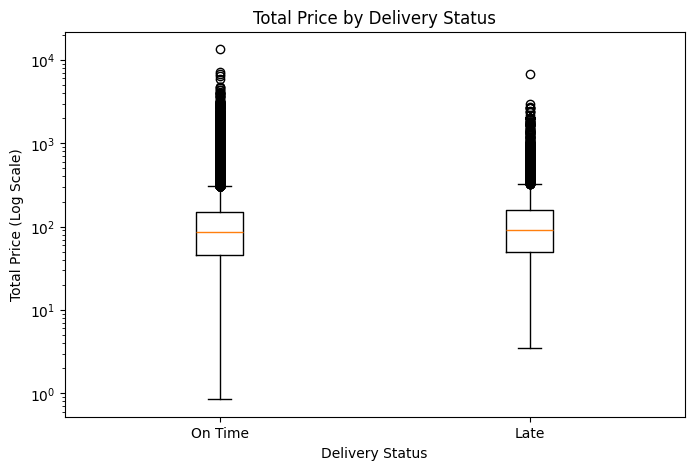

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df.loc[df['late_delivery'] == 0, 'total_price'].dropna(),
        df.loc[df['late_delivery'] == 1, 'total_price'].dropna()
    ],
    labels=['On Time', 'Late']
)

plt.yscale('log')
plt.title('Total Price by Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Total Price (Log Scale)')
plt.show()

## Customer state

In [ ]:
state_delay_rate = (
    df.groupby('customer_state')['late_delivery']
      .mean()
      .sort_values(ascending=False)
      * 100
)

state_delay_rate

,late_delivery
customer_state,
AL,23.664122
MA,20.028409
PI,16.204691
CE,15.567911
SE,15.315315
BA,14.080997
RJ,13.592074
TO,12.962963
RR,12.500000


In [ ]:
state_analysis = (
    df.groupby('customer_state')
      .agg(
          total_orders=('late_delivery', 'size'),
          late_orders=('late_delivery', 'sum'),
          late_rate=('late_delivery', 'mean')
      )
)

state_analysis['late_rate'] *= 100

state_analysis.sort_values('late_rate', ascending=False)

,total_orders,late_orders,late_rate
customer_state,,,
AL,393,93,23.664122
MA,704,141,20.028409
PI,469,76,16.204691
CE,1259,196,15.567911
SE,333,51,15.315315
BA,3210,452,14.080997
RJ,12213,1660,13.592074
TO,270,35,12.962963
RR,40,5,12.500000


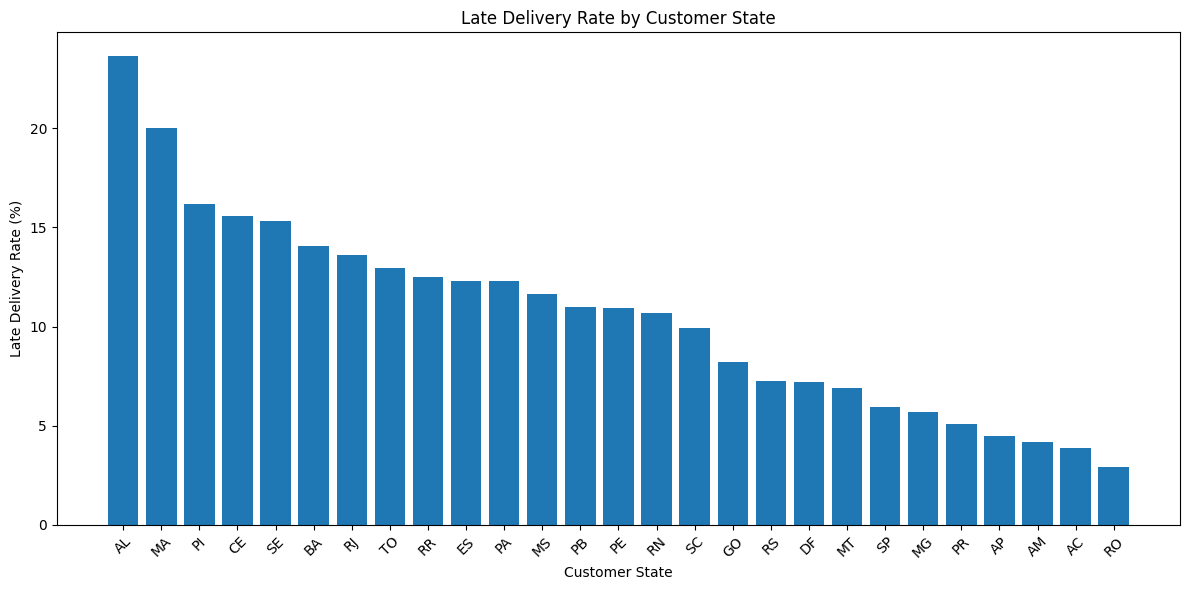

In [ ]:
import matplotlib.pyplot as plt

state_plot = state_analysis.sort_values('late_rate', ascending=False)

plt.figure(figsize=(12, 6))
plt.bar(state_plot.index, state_plot['late_rate'])
plt.title('Late Delivery Rate by Customer State')
plt.xlabel('Customer State')
plt.ylabel('Late Delivery Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Product category

In [ ]:
category_counts = (
    df['product_categories']
    .fillna('unknown')
    .str.split(', ')
    .explode()
    .value_counts()
)

category_counts.head(15)

,count
product_categories,
bed_bath_table,9130
health_beauty,8497
sports_leisure,7445
computers_accessories,6441
furniture_decor,6228
housewares,5634
watches_gifts,5395
telephony,4043
toys,3749


In [ ]:
category_delay = (
    df[['product_categories', 'late_delivery']]
    .assign(product_categories=lambda x: x['product_categories'].fillna('unknown'))
    .assign(product_categories=lambda x: x['product_categories'].str.split(', '))
    .explode('product_categories')
    .groupby('product_categories')['late_delivery']
    .agg(
        total_orders='count',
        late_orders='sum',
        late_rate='mean'
    )
)

category_delay['late_rate'] = category_delay['late_rate'] * 100

category_delay.sort_values(
    'total_orders',
    ascending=False
).head(15)

,total_orders,late_orders,late_rate
product_categories,,,
bed_bath_table,9130,808,8.849945
health_beauty,8497,773,9.097328
sports_leisure,7445,583,7.830759
computers_accessories,6441,502,7.793821
furniture_decor,6228,532,8.542068
housewares,5634,398,7.064253
watches_gifts,5395,466,8.637627
telephony,4043,348,8.607470
toys,3749,282,7.522006


## Payment type

In [ ]:
payment_delay = (
    df[['payment_types', 'late_delivery']]
    .assign(payment_types=lambda x: x['payment_types'].fillna('unknown'))
    .assign(payment_types=lambda x: x['payment_types'].str.split(', '))
    .explode('payment_types')
    .groupby('payment_types')['late_delivery']
    .agg(
        total_orders='count',
        late_orders='sum',
        late_rate='mean'
    )
)

payment_delay['late_rate'] *= 100

payment_delay.sort_values('total_orders', ascending=False)

,total_orders,late_orders,late_rate
payment_types,,,
credit_card,73279,5876,8.018668
boleto,18888,1699,8.995129
voucher,3632,258,7.103524
debit_card,1440,114,7.916667
unknown,1,1,100.000000


## Time pattern

In [ ]:
#Month
monthly_delay = (
    df.groupby('purchase_month')['late_delivery']
      .mean()
      .mul(100)
)

monthly_delay

,late_delivery
purchase_month,
1,6.237166
2,13.468590
3,17.159019
4,6.134899
5,6.649692
6,2.219049
7,4.229383
8,7.613582
9,5.219913


In [ ]:
#Year
df.groupby('purchase_year')['late_delivery'].agg(
    total_orders='count',
    late_orders='sum',
    late_rate='mean'
)

,total_orders,late_orders,late_rate
purchase_year,,,
2016,268,4,0.014925
2017,43310,2872,0.066313
2018,51511,4918,0.095475


In [ ]:
df['late_delivery'].groupby(df['purchase_year']).mean() * 100

,late_delivery
purchase_year,
2016,1.492537
2017,6.631263
2018,9.547475


In [ ]:
#Day of week
day_delay = (
    df.groupby('purchase_dayofweek')['late_delivery']
      .agg(
          total_orders='count',
          late_orders='sum',
          late_rate='mean'
      )
)

day_delay['late_rate'] *= 100

day_delay

,total_orders,late_orders,late_rate
purchase_dayofweek,,,
0,15488,1413,9.123192
1,15225,1310,8.604269
2,14841,1173,7.903780
3,14187,1080,7.612603
4,13495,1151,8.529085
5,10408,799,7.676787
6,11445,868,7.584098


In [ ]:
# Hour
hour_delay = (
    df.groupby('purchase_hour')['late_delivery']
      .agg(
          total_orders='count',
          late_orders='sum',
          late_rate='mean'
      )
)

hour_delay['late_rate'] *= 100

hour_delay

,total_orders,late_orders,late_rate
purchase_hour,,,
0,2295,208,9.063181
1,1114,95,8.527828
2,491,34,6.924644
3,256,15,5.859375
4,201,11,5.472637
5,179,12,6.703911
6,473,33,6.976744
7,1182,93,7.868020
8,2864,216,7.541899


In [ ]:
corr_cols = [
    'item_count',
    'total_price',
    'total_freight',
    'seller_count',
    'product_count',
    'total_payment_value',
    'max_installments',
    'payment_type_count',
    'category_count',
    'avg_product_weight_g',
    'purchase_year',
    'purchase_month',
    'purchase_dayofweek',
    'purchase_hour',
    'late_delivery'
]

corr_matrix = df[corr_cols].corr()

corr_matrix['late_delivery'].sort_values(ascending=False)

,late_delivery
late_delivery,1.000000
purchase_year,0.054289
total_freight,0.025366
avg_product_weight_g,0.023296
total_payment_value,0.017455
total_price,0.015659
max_installments,0.008824
purchase_hour,0.008427
payment_type_count,-0.005747
category_count,-0.013520


In [ ]:
corr_features = df[corr_cols[:-1]].corr()

corr_features

,item_count,total_price,total_freight,seller_count,product_count,total_payment_value,max_installments,payment_type_count,category_count,avg_product_weight_g,purchase_year,purchase_month,purchase_dayofweek,purchase_hour
item_count,1.000000,0.153583,0.439059,0.280078,0.471300,0.190044,0.067937,-0.006348,0.129988,-0.004869,0.001585,0.000572,-0.011769,-0.009881
total_price,0.153583,1.000000,0.410570,0.041914,0.062391,0.995940,0.313923,-0.008034,0.022797,0.332288,-0.001551,0.002106,-0.002929,0.004260
total_freight,0.439059,0.410570,1.000000,0.132225,0.197299,0.490849,0.199385,-0.002380,0.076218,0.502295,0.029082,0.004773,-0.003459,0.000460
seller_count,0.280078,0.041914,0.132225,1.000000,0.587837,0.053176,0.060939,0.007576,0.359786,-0.007297,0.018355,0.005359,0.010542,-0.003772
product_count,0.471300,0.062391,0.197299,0.587837,1.000000,0.079100,0.072459,0.003385,0.267181,-0.016415,-0.004203,0.009418,0.003992,0.003728
total_payment_value,0.190044,0.995940,0.490849,0.053176,0.079100,1.000000,0.319922,-0.007926,0.029355,0.367038,0.001362,0.002424,-0.003130,0.004118
max_installments,0.067937,0.313923,0.199385,0.060939,0.072459,0.319922,1.000000,-0.041551,0.038884,0.198155,-0.058359,0.031390,0.026222,0.012954
payment_type_count,-0.006348,-0.008034,-0.002380,0.007576,0.003385,-0.007926,-0.041551,1.000000,-0.001762,-0.001407,-0.019952,0.003644,-0.000872,0.005208
category_count,0.129988,0.022797,0.076218,0.359786,0.267181,0.029355,0.038884,-0.001762,1.000000,0.010230,0.023450,0.015482,0.002286,0.003292
avg_product_weight_g,-0.004869,0.332288,0.502295,-0.007297,-0.016415,0.367038,0.198155,-0.001407,0.010230,1.000000,-0.025463,-0.007143,-0.000174,0.009371


In [ ]:
x = x.drop(columns=['purchase_day'])

In [ ]:
x.shape

(95089, 17)

In [ ]:
numeric_features = [
    'item_count',
    'total_price',
    'total_freight',
    'seller_count',
    'product_count',
    'total_payment_value',
    'max_installments',
    'payment_type_count',
    'category_count',
    'avg_product_weight_g',
    'purchase_year',
    'purchase_month',
    'purchase_dayofweek',
    'purchase_hour'
]

categorical_features = [
    'customer_state',
    'payment_types',
    'product_categories'
]

In [ ]:
len(numeric_features), len(categorical_features)

(14, 3)

# Model Training

# 316 features dataset

In [ ]:
from sklearn.linear_model import LogisticRegression

model_316 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_316.fit(x_train_processed, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
y_pred_316 = model_316.predict(x_test_processed)

y_prob_316 = model_316.predict_proba(x_test_processed)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_316 = accuracy_score(y_test, y_pred_316)
precision_316 = precision_score(y_test, y_pred_316)
recall_316 = recall_score(y_test, y_pred_316)
f1_316 = f1_score(y_test, y_pred_316)
roc_auc_316 = roc_auc_score(y_test, y_prob_316)

print("316-Feature Logistic Regression Performance")
print("Accuracy :", accuracy_316)
print("Precision:", precision_316)
print("Recall   :", recall_316)
print("F1 Score :", f1_316)
print("ROC-AUC  :", roc_auc_316)

316-Feature Logistic Regression Performance
Accuracy : 0.6460721421810915
Precision: 0.12347117064647642
Recall   : 0.5439384220654265
F1 Score : 0.20125786163522014
ROC-AUC  : 0.63582307982918


In [ ]:
cm_316 = confusion_matrix(y_test, y_pred_316)

print("Confusion Matrix:")
print(cm_316)

Confusion Matrix:
[[11439  6020]
 [  711   848]]


In [ ]:
print("Minimum probability:", y_prob_316.min())
print("Maximum probability:", y_prob_316.max())
print("Mean probability:", y_prob_316.mean())

Minimum probability: 0.009543435277185036
Maximum probability: 0.8913237326568346
Mean probability: 0.4649978162433026


Since the dataset with 316 features return better predictions and 76 feature dataset is not sufficent for using with logistic regression as baseline , we will use 316 feature dataset for furhter predictions

Investigating why the model is not predicting all late deliveries

In [ ]:
feature_names = preprocessor.get_feature_names_out()

feature_importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": model_gb.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by="importance",
    ascending=False
)

feature_importance_df.head(20)

,feature,importance
11,num__purchase_month,0.402828
10,num__purchase_year,0.157059
32,cat__customer_state_RJ,0.098601
39,cat__customer_state_SP,0.066268
2,num__total_freight,0.056913
24,cat__customer_state_MG,0.022131
9,num__avg_product_weight_g,0.021942
18,cat__customer_state_BA,0.016857
31,cat__customer_state_PR,0.016034
23,cat__customer_state_MA,0.012861


In [ ]:
monthly_late_rate = (
    df.groupby("purchase_month")["late_delivery"]
    .mean()
    .sort_index()
)

monthly_late_rate

,late_delivery
purchase_month,
1,0.062372
2,0.134686
3,0.171590
4,0.061349
5,0.066497
6,0.022190
7,0.042294
8,0.076136
9,0.052199


In [ ]:
yearly_late_rate = (
    df.groupby("purchase_year")["late_delivery"]
    .mean()
    .sort_index()
) * 100

yearly_late_rate

,late_delivery
purchase_year,
2016,1.492537
2017,6.631263
2018,9.547475


In [ ]:
month_analysis = (
    df.groupby("purchase_month")["late_delivery"]
    .agg(
        total_orders="count",
        late_orders="sum",
        late_rate="mean"
    )
)

month_analysis["late_rate"] = month_analysis["late_rate"] * 100

month_analysis

,total_orders,late_orders,late_rate
purchase_month,,,
1,7792,486,6.237166
2,8182,1102,13.468590
3,9546,1638,17.159019
4,8688,533,6.134899
5,10211,679,6.649692
6,9103,202,2.219049
7,9434,399,4.229383
8,10455,796,7.613582
9,4138,216,5.219913


In [ ]:
year_analysis = (
    df.groupby("purchase_year")["late_delivery"]
    .agg(
        total_orders="count",
        late_orders="sum",
        late_rate="mean"
    )
)

year_analysis["late_rate"] = year_analysis["late_rate"] * 100

year_analysis

,total_orders,late_orders,late_rate
purchase_year,,,
2016,268,4,1.492537
2017,43310,2872,6.631263
2018,51511,4918,9.547475


In [ ]:
state_analysis = (
    df.groupby("customer_state")["late_delivery"]
    .agg(
        total_orders="count",
        late_orders="sum",
        late_rate="mean"
    )
)

state_analysis["late_rate"] = state_analysis["late_rate"] * 100

state_analysis.sort_values("late_rate", ascending=False)

,total_orders,late_orders,late_rate
customer_state,,,
AL,393,93,23.664122
MA,704,141,20.028409
PI,469,76,16.204691
CE,1259,196,15.567911
SE,333,51,15.315315
BA,3210,452,14.080997
RJ,12213,1660,13.592074
TO,270,35,12.962963
RR,40,5,12.500000


In [ ]:
df["freight_bin"] = pd.qcut(
    df["total_freight"],
    q=5,
    duplicates="drop"
)

freight_analysis = (
    df.groupby("freight_bin", observed=True)["late_delivery"]
    .agg(
        total_orders="count",
        late_orders="sum",
        late_rate="mean"
    )
)

freight_analysis["late_rate"] = freight_analysis["late_rate"] * 100

freight_analysis

,total_orders,late_orders,late_rate
freight_bin,,,
"(-0.001, 12.82]",19028,1172,6.159344
"(12.82, 15.63]",19036,1388,7.291448
"(15.63, 18.56]",18996,1696,8.928195
"(18.56, 27.36]",19024,1745,9.172624
"(27.36, 1794.96]",19005,1793,9.434359


In [ ]:
df["weight_bin"] = pd.qcut(
    df["avg_product_weight_g"],
    q=5,
    duplicates="drop"
)

weight_analysis = (
    df.groupby("weight_bin", observed=True)["late_delivery"]
    .agg(
        total_orders="count",
        late_orders="sum",
        late_rate="mean"
    )
)

weight_analysis["late_rate"] = weight_analysis["late_rate"] * 100

weight_analysis

,total_orders,late_orders,late_rate
weight_bin,,,
"(-0.001, 250.0]",21993,1634,7.429637
"(250.0, 500.0]",18167,1519,8.361314
"(500.0, 1000.0]",16951,1321,7.793051
"(1000.0, 2500.0]",19246,1624,8.438117
"(2500.0, 40425.0]",18716,1696,9.061765


Cross validation

In [140]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

model_gb_cv = GradientBoostingClassifier(
    random_state=42
)

cv_scores = cross_val_score(
    model_gb_cv,
    x_train_processed,
    y_train,
    cv=cv,
    scoring="f1"
)

print("F1 scores:", cv_scores)
print("Mean F1:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

F1 scores: [0.00479233 0.00319234 0.00160256 0.00319744 0.00159744]
Mean F1: 0.0028764241789247203
Standard deviation: 0.0011943255527059936


Understanding how well the model is able to detetc the late deliveries

In [141]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_train_array = y_train.to_numpy()

oof_prob_gb = np.zeros(len(y_train))

for train_idx, val_idx in cv.split(x_train_processed, y_train):

    model = GradientBoostingClassifier(
        random_state=42
    )

    model.fit(
        x_train_processed[train_idx],
        y_train_array[train_idx]
    )

    oof_prob_gb[val_idx] = model.predict_proba(
        x_train_processed[val_idx]
    )[:, 1]

print("OOF probabilities generated.")
print("Minimum:", oof_prob_gb.min())
print("Maximum:", oof_prob_gb.max())
print("Mean:", oof_prob_gb.mean())

OOF probabilities generated.
Minimum: 0.008308148137225637
Maximum: 0.8608071466518564
Mean: 0.08198291236910722


In [142]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_prob_gb
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]
best_precision = precision[best_index]
best_recall = recall[best_index]
best_f1 = f1_scores[best_index]

print("Best threshold:", best_threshold)
print("Precision:", best_precision)
print("Recall:", best_recall)
print("F1:", best_f1)

Best threshold: 0.1315402940629998
Precision: 0.2443140132061629
Recall: 0.4272654370489174
F1: 0.31086994569150167


In [143]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# train on all training data
final_gb = GradientBoostingClassifier(
    random_state=42
)

final_gb.fit(
    x_train_processed,
    y_train
)

# predict probabilities on untouched test data
y_prob_final = final_gb.predict_proba(
    x_test_processed
)[:, 1]

# apply the threshold selected using OOF predictions
final_threshold = 0.1315402940629998

y_pred_final = (
    y_prob_final >= final_threshold
).astype(int)

# evaluate
accuracy = accuracy_score(y_test, y_pred_final)
precision = precision_score(y_test, y_pred_final, zero_division=0)
recall = recall_score(y_test, y_pred_final)
f1 = f1_score(y_test, y_pred_final, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob_final)
cm = confusion_matrix(y_test, y_pred_final)

print("Final Gradient Boosting Results")
print("--------------------------------")
print("Threshold:", final_threshold)
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("ROC-AUC:", roc_auc)

print("\nConfusion Matrix:")
print(cm)

Final Gradient Boosting Results
--------------------------------
Threshold: 0.1315402940629998
Accuracy: 0.8485119360605742
Precision: 0.24340062111801242
Recall: 0.4021808851828095
F1: 0.30326481257557436
ROC-AUC: 0.7355104220899686

Confusion Matrix:
[[15510  1949]
 [  932   627]]


Hyperparameter tuning :- to check whether the model can do better as compared to earlier peroformance

In [145]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# create a validation set from the training data
x_train_sub, x_val, y_train_sub, y_val = train_test_split(
    x_train_processed,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

# a few targeted configurations
models = {
    "baseline": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "more_trees": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    "deeper_trees": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=4,
        random_state=42
    ),

    "regularized": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=5,
        random_state=42
    )
}

results = {}

for name, model in models.items():

    model.fit(x_train_sub, y_train_sub)

    y_prob = model.predict_proba(x_val)[:, 1]

    auc = roc_auc_score(y_val, y_prob)

    results[name] = auc

    print(f"{name}: ROC-AUC = {auc:.4f}")

print("\nBest configuration:")
print(max(results, key=results.get))

baseline: ROC-AUC = 0.7568
more_trees: ROC-AUC = 0.7565
deeper_trees: ROC-AUC = 0.7635
regularized: ROC-AUC = 0.7275

Best configuration:
deeper_trees


In [146]:
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_train_array = y_train.to_numpy()

oof_prob_tuned = np.zeros(len(y_train))

for train_idx, val_idx in cv.split(x_train_processed, y_train):

    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=4,
        random_state=42
    )

    model.fit(
        x_train_processed[train_idx],
        y_train_array[train_idx]
    )

    oof_prob_tuned[val_idx] = model.predict_proba(
        x_train_processed[val_idx]
    )[:, 1]

print("OOF probabilities generated.")
print("Minimum:", oof_prob_tuned.min())
print("Maximum:", oof_prob_tuned.max())
print("Mean:", oof_prob_tuned.mean())

OOF probabilities generated.
Minimum: 0.00675702011921445
Maximum: 0.9216227574310147
Mean: 0.08195941379028954


In [147]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_train,
    oof_prob_tuned
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)

best_threshold_tuned = thresholds[best_index]
best_precision_tuned = precision[best_index]
best_recall_tuned = recall[best_index]
best_f1_tuned = f1_scores[best_index]

print("Best threshold:", best_threshold_tuned)
print("Precision:", best_precision_tuned)
print("Recall:", best_recall_tuned)
print("F1:", best_f1_tuned)

Best threshold: 0.14277429471761144
Precision: 0.2592293726043978
Recall: 0.41218925421010427
F1: 0.3182859619316649


In [148]:
# train tuned model on all training data

final_tuned_gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

final_tuned_gb.fit(
    x_train_processed,
    y_train
)

# probabilities on untouched test data
y_prob_tuned_test = final_tuned_gb.predict_proba(
    x_test_processed
)[:, 1]

# use threshold selected from OOF predictions
final_threshold_tuned = 0.14277429471761144

y_pred_tuned_test = (
    y_prob_tuned_test >= final_threshold_tuned
).astype(int)

# evaluation
accuracy_tuned = accuracy_score(y_test, y_pred_tuned_test)
precision_tuned = precision_score(
    y_test,
    y_pred_tuned_test,
    zero_division=0
)
recall_tuned = recall_score(y_test, y_pred_tuned_test)
f1_tuned = f1_score(
    y_test,
    y_pred_tuned_test,
    zero_division=0
)
roc_auc_tuned = roc_auc_score(
    y_test,
    y_prob_tuned_test
)

cm_tuned = confusion_matrix(
    y_test,
    y_pred_tuned_test
)

print("Final Tuned Gradient Boosting Results")
print("--------------------------------------")
print("Threshold:", final_threshold_tuned)
print("Accuracy:", accuracy_tuned)
print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1:", f1_tuned)
print("ROC-AUC:", roc_auc_tuned)

print("\nConfusion Matrix:")
print(cm_tuned)

Final Tuned Gradient Boosting Results
--------------------------------------
Threshold: 0.14277429471761144
Accuracy: 0.857766326637922
Precision: 0.2598491198658843
Recall: 0.3976908274534958
F1: 0.31432192648922685
ROC-AUC: 0.7403459239847956

Confusion Matrix:
[[15693  1766]
 [  939   620]]


Targeted Feature Engineering

In [151]:
%whos

Variable                     Type                          Data/Info
--------------------------------------------------------------------
ColumnTransformer            ABCMeta                       <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DecisionTreeClassifier       ABCMeta                       <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GradientBoostingClassifier   ABCMeta                       <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
LassoCV                      ABCMeta                       <class 'sklearn.linear_mo<...>rdinate_descent.LassoCV'>
LogisticRegression           type                          <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                type                          <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                     ABCMeta                       <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier       ABCMeta                       <class 'sklearn.en

In [152]:
df.columns.tolist()

['order_id',
 'customer_id',
 'customer_state',
 'order_purchase_timestamp',
 'item_count',
 'total_price',
 'total_freight',
 'seller_count',
 'product_count',
 'total_payment_value',
 'max_installments',
 'payment_type_count',
 'payment_types',
 'category_count',
 'product_categories',
 'avg_product_weight_g',
 'late_delivery',
 'purchase_year',
 'purchase_month',
 'purchase_day',
 'purchase_dayofweek',
 'purchase_hour',
 'freight_bin',
 'weight_bin']

In [186]:
geo=pd.read_csv('/content/geolocation_processed.csv')
geo_zip = geo.groupby(
    "geolocation_zip_code_prefix"
)[["geolocation_lat", "geolocation_lng"]].mean().reset_index()

In [187]:
geo_zip.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,1001,-23.550227,-46.634039
1,1002,-23.547657,-46.634991
2,1003,-23.549000,-46.635582
3,1004,-23.549829,-46.634792
4,1005,-23.549547,-46.636406


In [188]:
geo_zip.shape

(6492, 3)

In [189]:
customers=pd.read_csv('/content/olist_customers_dataset.csv')
customers_geo = customers.merge(
    geo_zip,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)

In [190]:
customers_geo.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,14409.0,-20.499273,-47.396658
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,9790.0,-23.728396,-46.542250
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,1151.0,-23.531309,-46.656690
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,8775.0,-23.500670,-46.186348
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,13056.0,-22.975708,-47.143140


In [191]:
seller=pd.read_csv('/content/olist_sellers_dataset.csv')
sellers_geo = seller.merge(
    geo_zip,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
)

In [192]:
sellers_geo.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP,13023.0,-22.893317,-47.060596
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP,13844.0,-22.383375,-46.948142
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ,20031.0,-22.909446,-43.180240
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP,4195.0,-23.657118,-46.612730
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP,12914.0,-22.964546,-46.534214


In [193]:
orders=pd.read_csv('/content/order_processed (1).csv')
orders_geo = orders.merge(
    customers_geo[["customer_id", "geolocation_lat", "geolocation_lng"]],
    on="customer_id",
    how="left"
)

In [194]:
orders_geo.head()

,Unnamed: 0,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,geolocation_lat,geolocation_lng
0,0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,-23.577482,-46.587077
1,1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,NaN,NaN
2,2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,NaN,NaN
3,3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,NaN,NaN
4,4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,-23.676257,-46.514580


In [195]:
order_item=pd.read_csv('/content/order_item_processed.csv')
order_sellers_geo = order_item.merge(
    sellers_geo[
        ["seller_id", "geolocation_lat", "geolocation_lng"]
    ],
    on="seller_id",
    how="left"
)

In [196]:
order_sellers_geo.head()

,Unnamed: 0,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,geolocation_lat,geolocation_lng
0,0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,NaN,NaN
1,1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,-23.565754,-46.519097
2,2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,NaN,NaN
3,3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,-20.553651,-47.387145
4,4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,NaN,NaN


In [197]:
seller_counts = order_sellers_geo.groupby("order_id")["seller_id"].nunique()

seller_counts.value_counts().sort_index()

,count
seller_id,
1,97388
2,1219
3,54
4,3
5,2


In [198]:
order_distance = order_sellers_geo.merge(
    orders_geo[
        ["order_id", "geolocation_lat", "geolocation_lng"]
    ],
    on="order_id",
    how="left",
    suffixes=("_seller", "_customer")
)

In [199]:
order_distance.head()

,Unnamed: 0,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,geolocation_lat_seller,geolocation_lng_seller,geolocation_lat_customer,geolocation_lng_customer
0,0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,NaN,NaN,NaN,NaN
1,1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,-23.565754,-46.519097,-20.222506,-50.898951
2,2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,NaN,NaN,NaN,NaN
3,3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,-20.553651,-47.387145,-23.105968,-46.590277
4,4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,NaN,NaN,-23.243402,-46.827614


In [200]:
import numpy as np

lat1 = np.radians(order_distance["geolocation_lat_seller"])
lon1 = np.radians(order_distance["geolocation_lng_seller"])

lat2 = np.radians(order_distance["geolocation_lat_customer"])
lon2 = np.radians(order_distance["geolocation_lng_customer"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

earth_radius_km = 6371

order_distance["seller_customer_distance_km"] = (
    earth_radius_km * c
)

In [201]:
order_distance[
    [
        "order_id",
        "seller_id",
        "seller_customer_distance_km"
    ]
].head()

,order_id,seller_id,seller_customer_distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,NaN
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,585.068784
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,NaN
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,295.481182
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,NaN


In [202]:
order_distance["seller_customer_distance_km"].isna().sum()

np.int64(75088)

In [203]:
order_distance["seller_customer_distance_km"].notna().sum()

np.int64(37562)

In [204]:
order_avg_distance = (
    order_distance
    .groupby("order_id")["seller_customer_distance_km"]
    .mean()
    .reset_index()
)

In [205]:
order_avg_distance.head()

,order_id,seller_customer_distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,NaN
1,00018f77f2f0320c557190d7a144bdd3,585.068784
2,000229ec398224ef6ca0657da4fc703e,NaN
3,00024acbcdf0a6daa1e931b038114c75,295.481182
4,00042b26cf59d7ce69dfabb4e55b4fd9,NaN


In [206]:
order_avg_distance["seller_customer_distance_km"].isna().sum()

np.int64(65969)

In [207]:
order_avg_distance["seller_customer_distance_km"].notna().sum()

np.int64(32697)

In [208]:
df_distance = df.merge(
    order_avg_distance,
    on="order_id",
    how="left"
)

In [209]:
df_distance.columns.tolist()

['Unnamed: 0',
 'order_id',
 'order_item_id',
 'product_id',
 'seller_id',
 'shipping_limit_date',
 'price',
 'freight_value',
 'seller_customer_distance_km']

In [210]:
x.columns.tolist()

['customer_state',
 'item_count',
 'total_price',
 'total_freight',
 'seller_count',
 'product_count',
 'total_payment_value',
 'max_installments',
 'payment_type_count',
 'payment_types',
 'category_count',
 'product_categories',
 'avg_product_weight_g',
 'purchase_year',
 'purchase_month',
 'purchase_dayofweek',
 'purchase_hour']

In [211]:
y.head()

,late_delivery
0,0
1,0
2,0
3,0
4,0


In [212]:
y.shape

(95089,)

In [213]:
%whos

Variable                     Type                          Data/Info
--------------------------------------------------------------------
ColumnTransformer            ABCMeta                       <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DecisionTreeClassifier       ABCMeta                       <class 'sklearn.tree._cla<...>.DecisionTreeClassifier'>
GradientBoostingClassifier   ABCMeta                       <class 'sklearn.ensemble.<...>dientBoostingClassifier'>
LassoCV                      ABCMeta                       <class 'sklearn.linear_mo<...>rdinate_descent.LassoCV'>
LogisticRegression           type                          <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
OneHotEncoder                type                          <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Pipeline                     ABCMeta                       <class 'sklearn.pipeline.Pipeline'>
RandomForestClassifier       ABCMeta                       <class 'sklearn.en

In [214]:
orders.shape

(98037, 9)

In [215]:
orders.columns.tolist()

['Unnamed: 0',
 'order_id',
 'customer_id',
 'order_status',
 'order_purchase_timestamp',
 'order_approved_at',
 'order_delivered_carrier_date',
 'order_delivered_customer_date',
 'order_estimated_delivery_date']

In [216]:
x.index[:10]

RangeIndex(start=0, stop=10, step=1)

In [217]:
y.index[:10]

RangeIndex(start=0, stop=10, step=1)